In [72]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

In [4]:
chm_heights = pd.read_csv("chm_heights.csv")
fieldwork_heights = pd.read_csv("lizirias_fieldwork_20260707.csv")
crown_areas = pd.read_csv("crown_areas_trees.csv")

chm_heights.head(), fieldwork_heights.head(), crown_areas.head()

(       id tree_id  chm_heightsmax
 0  2051.0  p205t1        0.734657
 1  2052.0  p205t2        1.005630
 2  2053.0  p205t3        1.002468
 3  2054.0  p205t4        6.852749
 4  2055.0  p205t5        9.050510,
    plot_id  tree_id       d_cm  pap_cm  ct_mm  ht_m  hcb_m  yd  papi  di  ...  \
 0       10        1  15.406198    48.4    NaN   5.1    1.9 NaN   NaN NaN  ...   
 1       10        2  46.700000     NaN   22.0  10.4    2.5 NaN   NaN NaN  ...   
 2       10        3  63.800000     NaN   25.0  10.0    3.2 NaN   NaN NaN  ...   
 3       10        4  13.528170    42.5    NaN   5.4    1.8 NaN   NaN NaN  ...   
 4       10        5  20.849298    65.5    NaN   6.9    1.9 NaN   NaN NaN  ...   
 
    ctj  ctk  species    observations  Unnamed: 18  Unnamed: 19 area1 area2  \
 0  NaN  NaN       Sb  Never debarked          NaN          NaN   NaN   NaN   
 1  NaN  NaN       Sb             NaN          NaN          NaN   NaN   NaN   
 2  NaN  NaN       Sb    Damaged bark          NaN        

if using a csv with fucked up ids:

In [5]:
fieldwork_heights['tree_id'] = (
    'p'
    + fieldwork_heights['plot_id'].astype(str).str.strip()
    + 't'
    + fieldwork_heights['tree_id'].astype(str).str.strip()
)
fieldwork_heights.head()

,plot_id,tree_id,d_cm,pap_cm,ct_mm,ht_m,hcb_m,yd,papi,di,...,ctj,ctk,species,observations,Unnamed: 18,Unnamed: 19,area1,area2,area3,d_est
0,10,p10t1,15.406198,48.4,NaN,5.1,1.9,NaN,NaN,NaN,...,NaN,NaN,Sb,Never debarked,NaN,NaN,NaN,NaN,NaN,NaN
1,10,p10t2,46.700000,NaN,22.0,10.4,2.5,NaN,NaN,NaN,...,NaN,NaN,Sb,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,10,p10t3,63.800000,NaN,25.0,10.0,3.2,NaN,NaN,NaN,...,NaN,NaN,Sb,Damaged bark,NaN,NaN,NaN,NaN,NaN,NaN
3,10,p10t4,13.528170,42.5,NaN,5.4,1.8,NaN,NaN,NaN,...,NaN,NaN,Sb,Never debarked,NaN,NaN,NaN,NaN,NaN,NaN
4,10,p10t5,20.849298,65.5,NaN,6.9,1.9,NaN,NaN,NaN,...,NaN,NaN,Sb,Never debarked,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
fieldwork_heights = fieldwork_heights[['tree_id', 'ht_m', 'd_cm']]
print(fieldwork_heights.head())

  tree_id  ht_m       d_cm
0   p10t1   5.1  15.406198
1   p10t2  10.4  46.700000
2   p10t3  10.0  63.800000
3   p10t4   5.4  13.528170
4   p10t5   6.9  20.849298


In [7]:
height_dcm = fieldwork_heights[['tree_id', 'ht_m', 'd_cm']]
height_dcm.head()

,tree_id,ht_m,d_cm
0,p10t1,5.1,15.406198
1,p10t2,10.4,46.700000
2,p10t3,10.0,63.800000
3,p10t4,5.4,13.528170
4,p10t5,6.9,20.849298


Not needed if using csv with tree_id

In [5]:
# convert location_id to lowercase and rename to tree_id
fieldwork_heights['location_id'] = fieldwork_heights['location_id'].str.lower()
fieldwork_heights = fieldwork_heights.rename(columns={'location_id': 'tree_id'})
fieldwork_heights.head()

,tree_id,ht_m,d_cm
0,p175t1,12.2,70.0
1,p175t2,9.0,47.5
2,p175t3,6.5,30.8
3,p175t4,8.4,31.5
4,p175t5,5.9,15.6


In [8]:
merged_heights = pd.merge(chm_heights, fieldwork_heights, on='tree_id', how='inner')
merged_heights.head()

,id,tree_id,chm_heightsmax,ht_m,d_cm
0,2051.0,p205t1,0.734657,2.7,6.302536
1,2052.0,p205t2,1.005630,3.3,7.703099
2,2053.0,p205t3,1.002468,4.0,8.912677
3,2054.0,p205t4,6.852749,3.8,38.610989
4,2055.0,p205t5,9.050510,8.9,40.202539


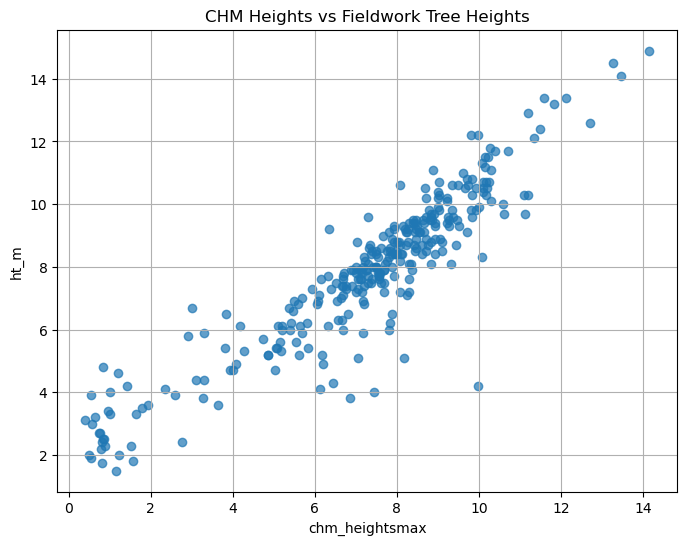

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(merged_heights['chm_heightsmax'], merged_heights['ht_m'], alpha=0.7)
plt.xlabel('chm_heightsmax')
plt.ylabel('ht_m')
plt.title('CHM Heights vs Fieldwork Tree Heights')
plt.grid(True)
plt.show()

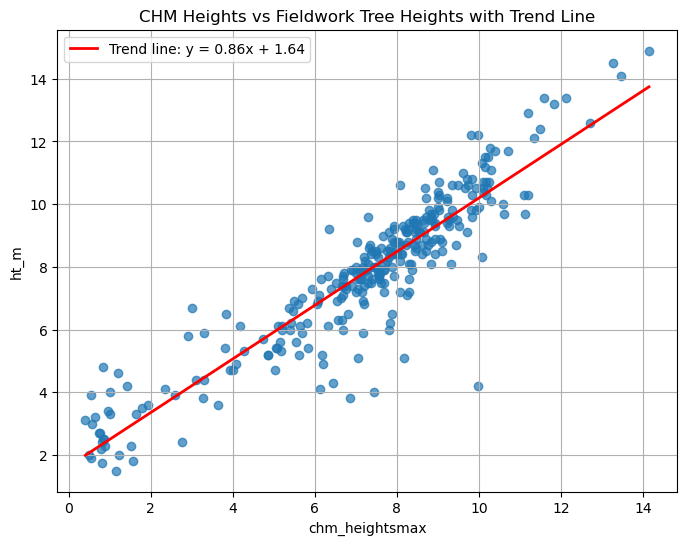

In [24]:
import numpy as np

x = merged_heights['chm_heightsmax']
y = merged_heights['ht_m']
coeffs = np.polyfit(x, y, 1)
trend_x = np.linspace(x.min(), x.max(), 100)
trend_y = np.polyval(coeffs, trend_x)

plt.figure(figsize=(8, 6))
plt.scatter(x, y, alpha=0.7)
plt.plot(trend_x, trend_y, color='red', linewidth=2, label=f'Trend line: y = {coeffs[0]:.2f}x + {coeffs[1]:.2f}')
plt.xlabel('chm_heightsmax')
plt.ylabel('ht_m')
plt.title('CHM Heights vs Fieldwork Tree Heights with Trend Line')
plt.legend()
plt.grid(True)
plt.show()

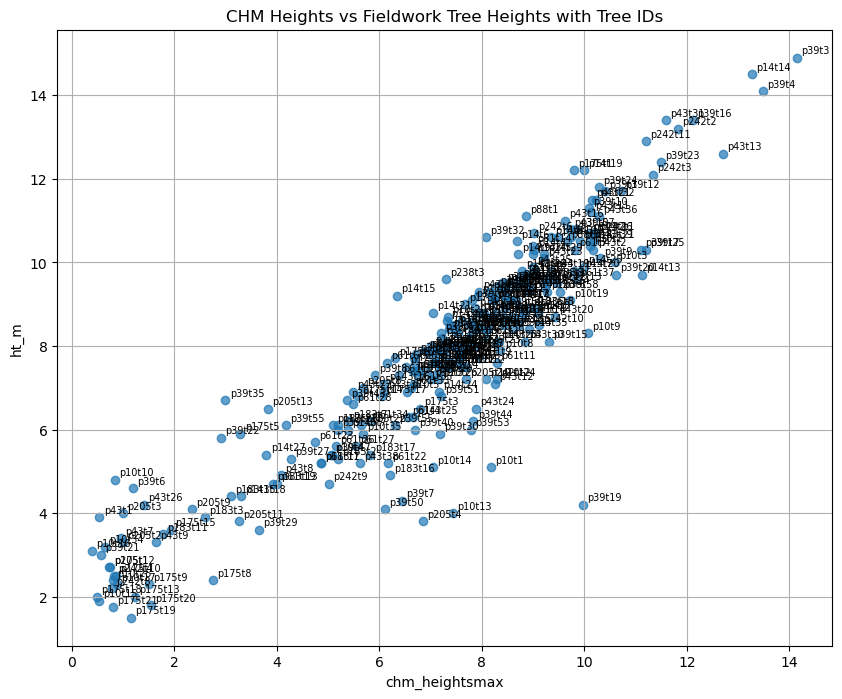

In [15]:
plt.figure(figsize=(10, 8))
plt.scatter(merged_heights['chm_heightsmax'], merged_heights['ht_m'], alpha=0.7)
for _, row in merged_heights.iterrows():
    plt.annotate(
        row['tree_id'],
        (row['chm_heightsmax'], row['ht_m']),
        textcoords="offset points",
        xytext=(3, 3),
        fontsize=7
    )
plt.xlabel('chm_heightsmax')
plt.ylabel('ht_m')
plt.title('CHM Heights vs Fieldwork Tree Heights with Tree IDs')
plt.grid(True)
plt.show()

In [16]:
# Calculate the error (residuals) between CHM heights and fieldwork heights
merged_heights['error'] = merged_heights['ht_m'] - merged_heights['chm_heightsmax']

# Display statistics about the errors
print("Error Statistics:")
print(f"Mean Error: {merged_heights['error'].mean():.4f}")
print(f"Std Dev: {merged_heights['error'].std():.4f}")
print(f"Min Error: {merged_heights['error'].min():.4f}")
print(f"Max Error: {merged_heights['error'].max():.4f}")
print(f"RMSE: {np.sqrt((merged_heights['error']**2).mean()):.4f}")
print("\nFirst few rows with errors:")
print(merged_heights[['tree_id', 'chm_heightsmax', 'ht_m', 'error']].head(10))

Error Statistics:
Mean Error: 0.5990
Std Dev: 1.0689
Min Error: -5.7702
Max Error: 3.9633
RMSE: 1.2238

First few rows with errors:
   tree_id  chm_heightsmax  ht_m     error
0   p205t1        0.734657   2.7  1.965343
1   p205t2        1.005630   3.3  2.294370
2   p205t3        1.002468   4.0  2.997532
3   p205t4        6.852749   3.8 -3.052749
4   p205t5        9.050510   8.9 -0.150510
5   p205t6        7.879974   8.4  0.520026
6   p205t7        7.676418   7.9  0.223582
7   p205t8        5.673393   7.0  1.326607
8   p205t9        2.339153   4.1  1.760847
9  p205t10        7.687588   7.2 -0.487588


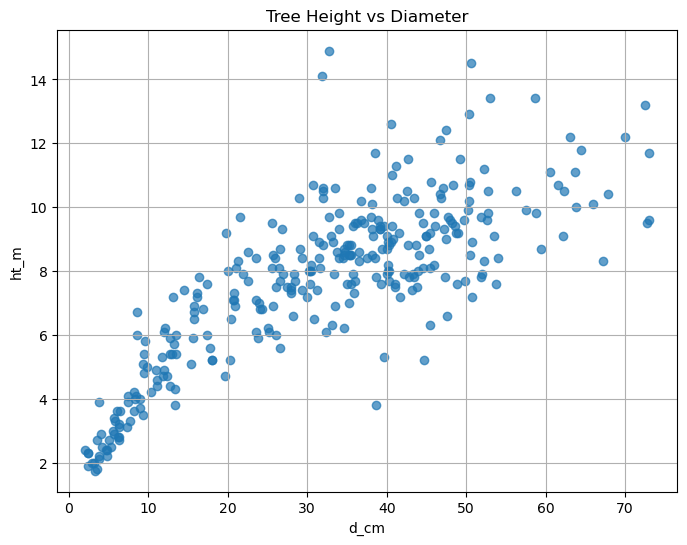

In [30]:
subset = height_dcm.dropna(subset=['d_cm'])

plt.figure(figsize=(8, 6))
plt.scatter(subset['d_cm'], subset['ht_m'], alpha=0.7)
plt.xlabel('d_cm')
plt.ylabel('ht_m')
plt.title('Tree Height vs Diameter')
plt.grid(True)
plt.show()

## it is also worth comparing crown area, some index of height/distance to closest crown, crown density/ha (calculated per tree with tree in centre?)

In [25]:
merged_fieldheight_crown = pd.merge(fieldwork_heights, crown_areas, on='tree_id', how='inner')
merged_fieldheight_crown.head()

,tree_id,ht_m,d_cm,area_m2
0,p10t1,5.1,15.406198,3.797820
1,p10t2,10.4,46.700000,25.516840
2,p10t3,10.0,63.800000,23.658146
3,p10t4,5.4,13.528170,4.097521
4,p10t5,6.9,20.849298,7.422642


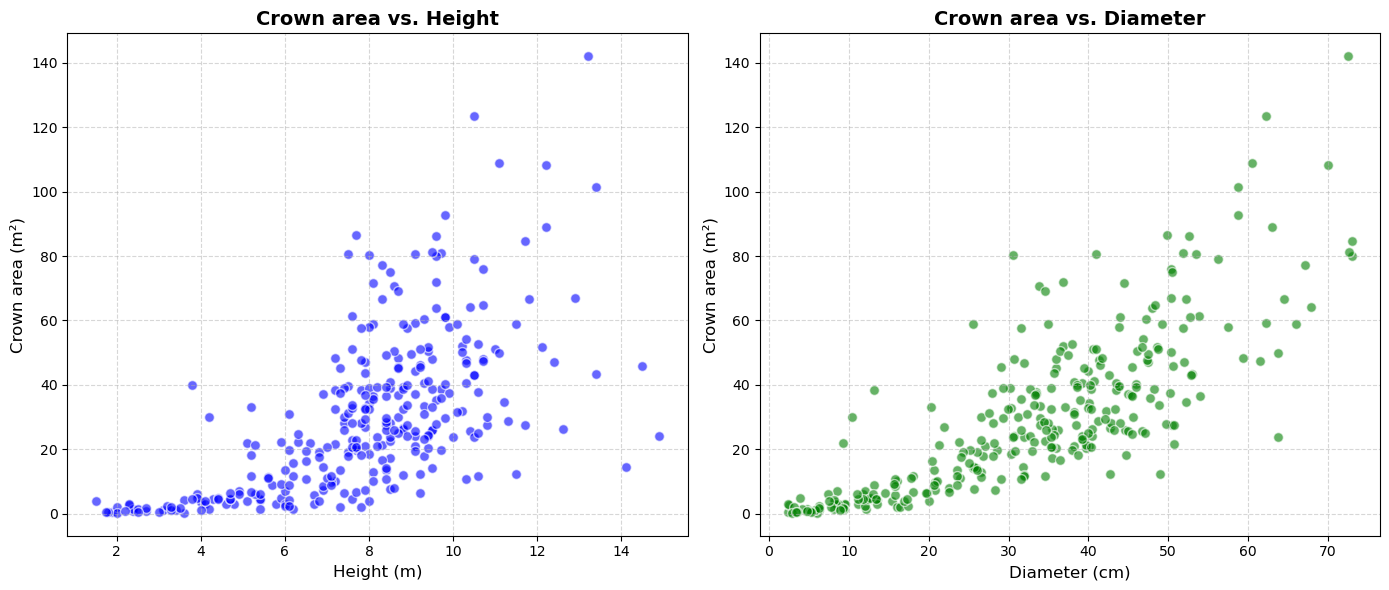

In [26]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# --- Graph 1: Area (m²) vs Height (m) ---
ax1.scatter(merged_fieldheight_crown['ht_m'], merged_fieldheight_crown['area_m2'], color='blue', alpha=0.6, edgecolors='w', s=50)
ax1.set_xlabel('Height (m)', fontsize=12)
ax1.set_ylabel('Crown area (m²)', fontsize=12)
ax1.set_title('Crown area vs. Height', fontsize=14, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)

# --- Graph 2: Diameter (cm) vs Area (m²) ---
ax2.scatter(merged_fieldheight_crown['d_cm'], merged_fieldheight_crown['area_m2'], color='green', alpha=0.6, edgecolors='w', s=50)
ax2.set_xlabel('Diameter (cm)', fontsize=12)
ax2.set_ylabel('Crown area (m²)', fontsize=12)
ax2.set_title('Crown area vs. Diameter', fontsize=14, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.5)

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

In [27]:
from scipy.stats import spearmanr
# non-linear regression for area vs diameter
clean_df = merged_fieldheight_crown.dropna(subset=['d_cm', 'area_m2'])
correlation, p_value = spearmanr(clean_df['d_cm'], clean_df['area_m2'])

print(f"Spearman's Rho: {correlation:.4f}")
print(f"P-value: {p_value:.4f}")

Spearman's Rho: 0.8346
P-value: 0.0000


In [28]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score


X = clean_df['d_cm'].values.reshape(-1, 1) # Independent variable
y = clean_df['area_m2'].values              # Dependent variable

# 1. Create polynomial features (degree 2: x and x^2)
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)

# 2. Fit the model
model = LinearRegression()
model.fit(X_poly, y)

# 3. Predict and calculate R-squared
y_pred = model.predict(X_poly)
r2_score_non_linear = r2_score(y, y_pred)

print(f"Polynomial R² (Degree 2): {r2_score_non_linear:.4f}")
print(f"Model coefficients: {model.coef_}")
print(f"Intercept: {model.intercept_}")

Polynomial R² (Degree 2): 0.6600
Model coefficients: [0.         0.56963745 0.00960835]
Intercept: -1.3727811425403722


In [35]:
merged_fieldheight_crown['area_height_ratio'] = merged_fieldheight_crown['area_m2'] / merged_fieldheight_crown['ht_m']

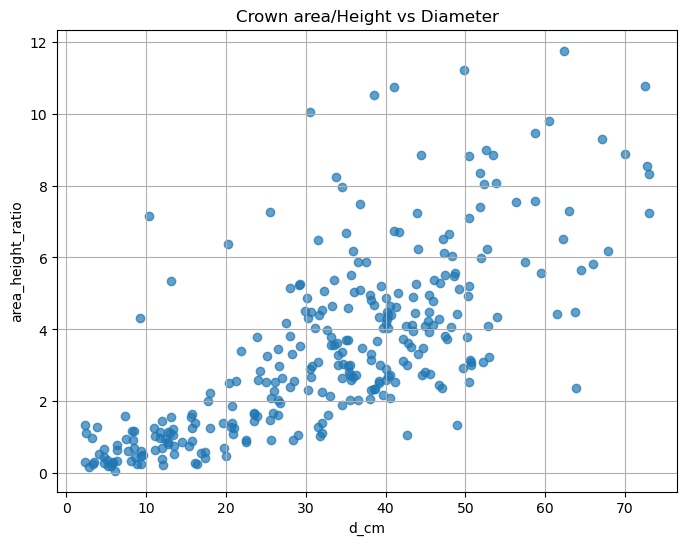

In [36]:
plt.figure(figsize=(8, 6))
plt.scatter(merged_fieldheight_crown['d_cm'], merged_fieldheight_crown['area_height_ratio'], alpha=0.7)
plt.xlabel('d_cm')
plt.ylabel('area_height_ratio')
plt.title('Crown area/Height vs Diameter')
plt.grid(True)
plt.show()

In [37]:

# non-linear regression for area height ratio vs diameter
clean_df = merged_fieldheight_crown.dropna(subset=['d_cm', 'area_height_ratio'])
correlation, p_value = spearmanr(clean_df['d_cm'], clean_df['area_height_ratio'])

print(f"Spearman's Rho: {correlation:.4f}")
print(f"P-value: {p_value:.4f}")

Spearman's Rho: 0.7582
P-value: 0.0000


Point cloud density? /distance to nearest point? or distance to nearest crown? Density probably better


In [10]:
density_df = pd.read_csv("height_area_density_tree.csv")
density_df.head()

,tree_id,area_m2,height_max,point_count_30m_count,point_count_30m_max
0,p205t1,1.709207,NaN,NaN,NaN
1,p205t2,2.057276,NaN,NaN,NaN
2,p205t3,1.034073,NaN,NaN,NaN
3,p205t4,39.923133,6.808346,2.0,7.0
4,p205t5,39.946031,9.025441,1.0,13.0


In [11]:
merged_density = pd.merge(merged_fieldheight_crown, density_df, on='tree_id', how='inner')
merged_density.head()

,tree_id,ht_m,d_cm,area_m2_x,area_m2_y,height_max,point_count_30m_count,point_count_30m_max
0,p10t1,5.1,15.406198,3.797820,3.797820,NaN,NaN,NaN
1,p10t2,10.4,46.700000,25.516840,25.516840,NaN,NaN,NaN
2,p10t3,10.0,63.800000,23.658146,23.658146,10.577975,1.0,21.0
3,p10t4,5.4,13.528170,4.097521,4.097521,NaN,NaN,NaN
4,p10t5,6.9,20.849298,7.422642,7.422642,5.550296,1.0,17.0


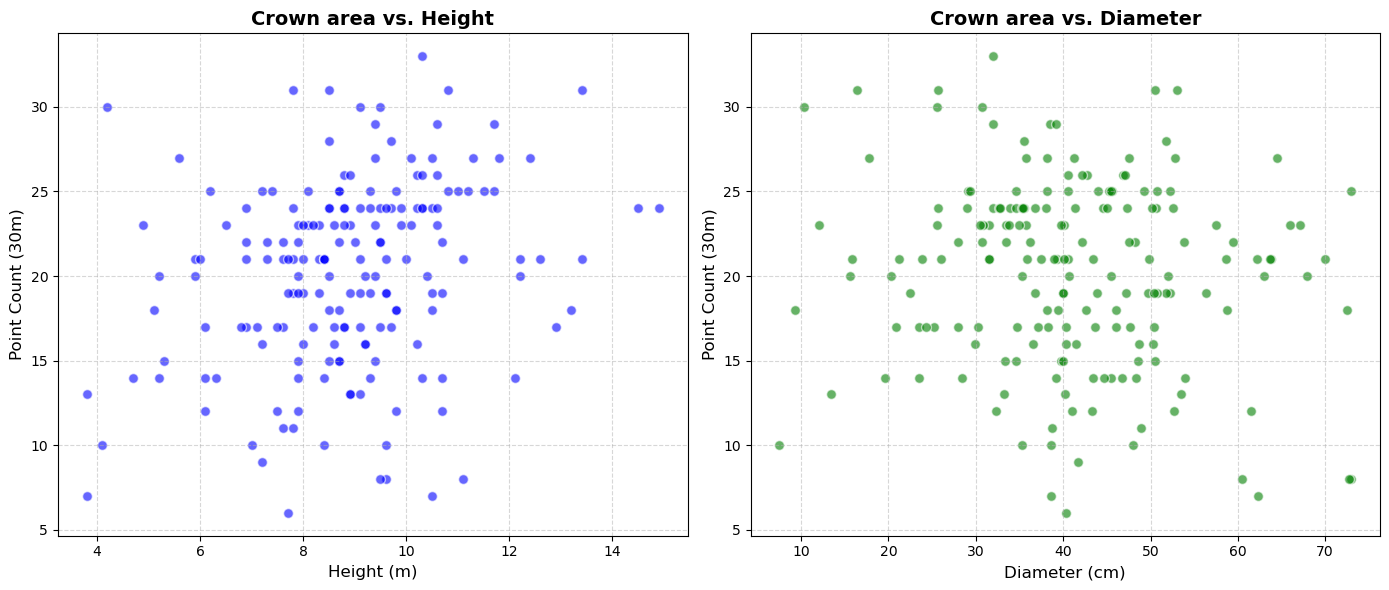

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# --- Graph 1: Area (m²) vs Height (m) ---
ax1.scatter(merged_density['ht_m'], merged_density['point_count_30m_max'], color='blue', alpha=0.6, edgecolors='w', s=50)
ax1.set_xlabel('Height (m)', fontsize=12)
ax1.set_ylabel('Point Count (30m)', fontsize=12)
ax1.set_title('Crown area vs. Height', fontsize=14, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)

# --- Graph 2: Diameter (cm) vs Area (m²) ---
ax2.scatter(merged_density['d_cm'], merged_density['point_count_30m_max'], color='green', alpha=0.6, edgecolors='w', s=50)
ax2.set_xlabel('Diameter (cm)', fontsize=12)
ax2.set_ylabel('Point Count (30m)', fontsize=12)
ax2.set_title('Crown area vs. Diameter', fontsize=14, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.5)

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

In [16]:
merged_density['density_ratio'] = merged_density['area_m2_x'] / merged_density['point_count_30m_max']

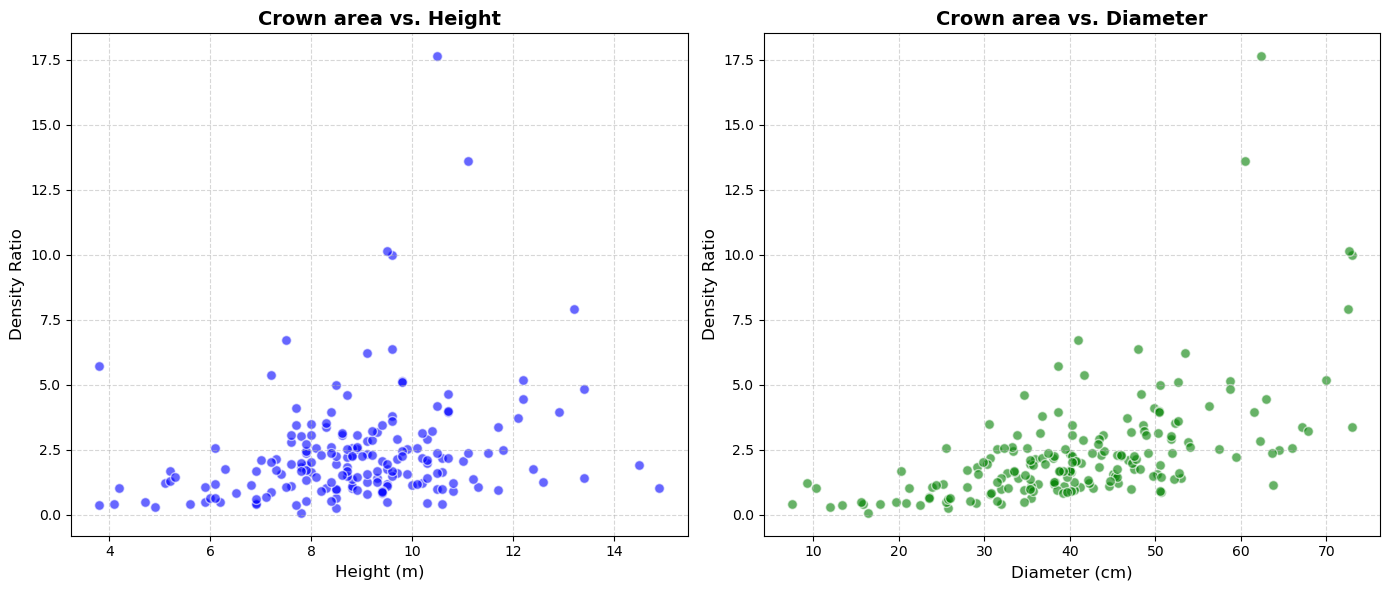

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# --- Graph 1: Area (m²) vs Height (m) ---
ax1.scatter(merged_density['ht_m'], merged_density['density_ratio'], color='blue', alpha=0.6, edgecolors='w', s=50)
ax1.set_xlabel('Height (m)', fontsize=12)
ax1.set_ylabel('Density Ratio', fontsize=12)
ax1.set_title('Area/Density ratio vs. Height', fontsize=14, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)

# --- Graph 2: Diameter (cm) vs Area (m²) ---
ax2.scatter(merged_density['d_cm'], merged_density['density_ratio'], color='green', alpha=0.6, edgecolors='w', s=50)
ax2.set_xlabel('Diameter (cm)', fontsize=12)
ax2.set_ylabel('Density Ratio', fontsize=12)
ax2.set_title('Area/Density ratio vs. Diameter', fontsize=14, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.5)

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

In [22]:
from scipy.stats import spearmanr
# non-linear regression for area vs diameter
clean_df = merged_density.dropna(subset=['d_cm', 'density_ratio'])
correlation, p_value = spearmanr(clean_df['d_cm'], clean_df['density_ratio'])

print(f"Spearman's Rho: {correlation:.4f}")
print(f"P-value: {p_value:.4f}")

Spearman's Rho: 0.6200
P-value: 0.0000


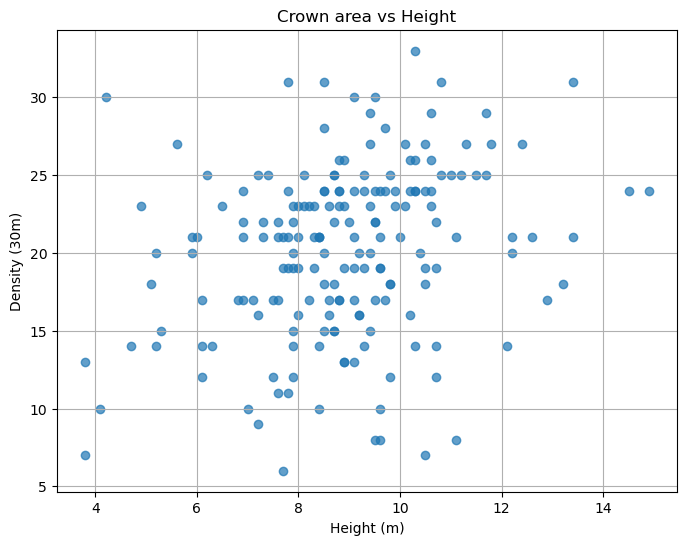

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(merged_density['ht_m'], merged_density['point_count_30m_max'], alpha=0.7)
plt.xlabel('Height (m)')
plt.ylabel('Density (30m)')
plt.title('Height vs Density (30m)')
plt.grid(True)
plt.show()

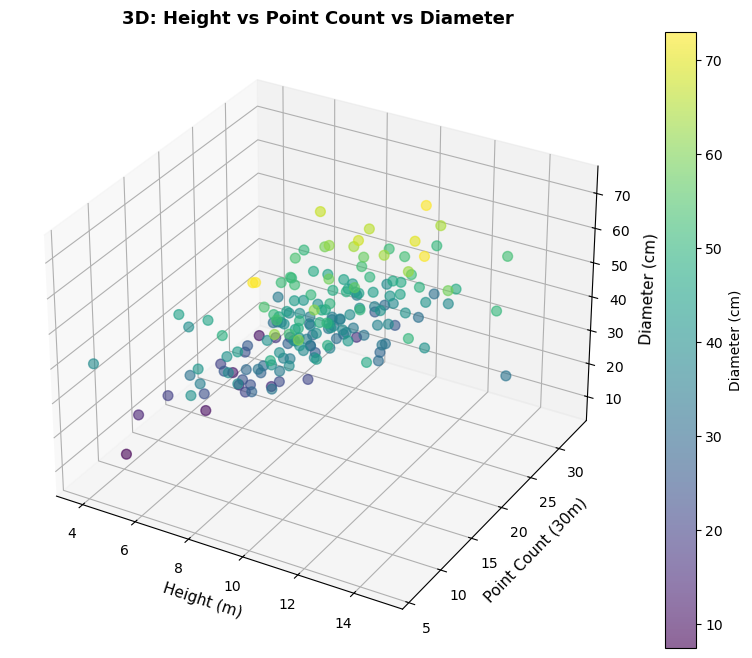

In [21]:
from mpl_toolkits.mplot3d import Axes3D

# Remove rows with NaN values in the required columns
clean_3d_df = merged_density.dropna(subset=['ht_m', 'point_count_30m_max', 'd_cm'])

# Create 3D plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Create scatter plot
scatter = ax.scatter(clean_3d_df['ht_m'], 
                     clean_3d_df['point_count_30m_max'], 
                     clean_3d_df['d_cm'], 
                     c=clean_3d_df['d_cm'], 
                     cmap='viridis', 
                     alpha=0.6, 
                     s=50)

ax.set_xlabel('Height (m)', fontsize=11)
ax.set_ylabel('Point Count (30m)', fontsize=11)
ax.set_zlabel('Diameter (cm)', fontsize=11)
ax.set_title('3D: Height vs Point Count vs Diameter', fontsize=13, fontweight='bold')

plt.colorbar(scatter, ax=ax, label='Diameter (cm)')
plt.show()

Density does not appear to have a very tight relationship with area_m2. Try height/density ratio, but not hopeful. 

## Heatmap for all variables

note to self: this uav variables is not correct. It is from the max_heights, which is why it has denisities. Need to use GPS points per plot for density, which can be in field_variables

In [133]:
chm_heights = pd.read_csv("chm_heights.csv")
crown_areas = pd.read_csv("crown_areas_trees.csv")
field_variables = pd.read_csv("trees_biomass.csv", delimiter=';')
chm_heights.head(), crown_areas.head(), field_variables.head()

(       id tree_id  chm_heightsmax
 0  2051.0  p205t1        0.734657
 1  2052.0  p205t2        1.005630
 2  2053.0  p205t3        1.002468
 3  2054.0  p205t4        6.852749
 4  2055.0  p205t5        9.050510,
   tree_id    area_m2
 0  p205t1   1.709207
 1  p205t2   2.057276
 2  p205t3   1.034073
 3  p205t4  39.923133
 4  p205t5  39.946031,
    plot_id  tree_id  d_cm  pap_cm  ct_mm  ht_m  hcb_m  yd  papi  di  ...  cti  \
 0       10        1   NaN    48.4    NaN   5.1    1.9 NaN   NaN NaN  ...  NaN   
 1       10        2  46.7     NaN   22.0  10.4    2.5 NaN   NaN NaN  ...  NaN   
 2       10        3  63.8     NaN   25.0  10.0    3.2 NaN   NaN NaN  ...  NaN   
 3       10        4   NaN    42.5    NaN   5.4    1.8 NaN   NaN NaN  ...  NaN   
 4       10        5   NaN    65.5    NaN   6.9    1.9 NaN   NaN NaN  ...  NaN   
 
    ctj  ctk    observations  du_cm  reg_leaves reg_woody pt_leaves  \
 0  NaN  NaN  Never debarked   11.3        5.04     50.44      4.26   
 1  NaN  NaN        

In [134]:
field_variables['tree_id'] = (
    'p'
    + field_variables['plot_id'].astype(str).str.strip()
    + 't'
    + field_variables['tree_id'].astype(str).str.strip()
)
field_variables.head()

,plot_id,tree_id,d_cm,pap_cm,ct_mm,ht_m,hcb_m,yd,papi,di,...,cti,ctj,ctk,observations,du_cm,reg_leaves,reg_woody,pt_leaves,pt_branches,pt_stem
0,10,p10t1,NaN,48.4,NaN,5.1,1.9,NaN,NaN,NaN,...,NaN,NaN,NaN,Never debarked,11.3,5.04,50.44,4.26,17.62,24.44
1,10,p10t2,46.7,NaN,22.0,10.4,2.5,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,42.3,35.58,1322.74,32.35,250.77,1040.84
2,10,p10t3,63.8,NaN,25.0,10.0,3.2,NaN,NaN,NaN,...,NaN,NaN,NaN,Damaged bark,58.8,50.31,2539.56,48.65,442.40,2499.67
3,10,p10t4,NaN,42.5,NaN,5.4,1.8,NaN,NaN,NaN,...,NaN,NaN,NaN,Never debarked,9.8,4.46,39.23,3.76,14.42,18.02
4,10,p10t5,NaN,65.5,NaN,6.9,1.9,NaN,NaN,NaN,...,NaN,NaN,NaN,Never debarked,15.72,8.92,125.45,7.35,38.68,67.31


In [135]:
# count amount of trees for each plot_id, and add this. to a new variable for each tree in that plot
tree_counts = field_variables.groupby('plot_id').size()
field_variables['tree_count'] = field_variables['plot_id'].map(tree_counts)
field_variables.head()

,plot_id,tree_id,d_cm,pap_cm,ct_mm,ht_m,hcb_m,yd,papi,di,...,ctj,ctk,observations,du_cm,reg_leaves,reg_woody,pt_leaves,pt_branches,pt_stem,tree_count
0,10,p10t1,NaN,48.4,NaN,5.1,1.9,NaN,NaN,NaN,...,NaN,NaN,Never debarked,11.3,5.04,50.44,4.26,17.62,24.44,35
1,10,p10t2,46.7,NaN,22.0,10.4,2.5,NaN,NaN,NaN,...,NaN,NaN,NaN,42.3,35.58,1322.74,32.35,250.77,1040.84,35
2,10,p10t3,63.8,NaN,25.0,10.0,3.2,NaN,NaN,NaN,...,NaN,NaN,Damaged bark,58.8,50.31,2539.56,48.65,442.40,2499.67,35
3,10,p10t4,NaN,42.5,NaN,5.4,1.8,NaN,NaN,NaN,...,NaN,NaN,Never debarked,9.8,4.46,39.23,3.76,14.42,18.02,35
4,10,p10t5,NaN,65.5,NaN,6.9,1.9,NaN,NaN,NaN,...,NaN,NaN,Never debarked,15.72,8.92,125.45,7.35,38.68,67.31,35


In [136]:
# remove plot_id, yd, papi, di, papj, dj, papk, cti, ctj, ctk, obervations from field_variables
field_variables = field_variables.drop(columns=['plot_id', 'd_cm', 'ct_mm', 'pap_cm', 'yd', 'papi', 'di', 'papj', 'dj', 'papk', 'cti', 'ctj', 'ctk', 'observations'])
field_variables.head()

,tree_id,ht_m,hcb_m,du_cm,reg_leaves,reg_woody,pt_leaves,pt_branches,pt_stem,tree_count
0,p10t1,5.1,1.9,11.3,5.04,50.44,4.26,17.62,24.44,35
1,p10t2,10.4,2.5,42.3,35.58,1322.74,32.35,250.77,1040.84,35
2,p10t3,10.0,3.2,58.8,50.31,2539.56,48.65,442.40,2499.67,35
3,p10t4,5.4,1.8,9.8,4.46,39.23,3.76,14.42,18.02,35
4,p10t5,6.9,1.9,15.72,8.92,125.45,7.35,38.68,67.31,35


In [137]:
# check that reg_woody, reg_leaves, pt_stem, pt_branches, pt_leaves are numeric
numeric_columns = ['reg_woody', 'reg_leaves', 'pt_stem', 'pt_branches', 'pt_leaves', 'ht_m', 'hcb_m', 'du_cm', 'tree_count']
field_variables[numeric_columns] = field_variables[numeric_columns].apply(pd.to_numeric, errors='coerce')
field_variables.head()

,tree_id,ht_m,hcb_m,du_cm,reg_leaves,reg_woody,pt_leaves,pt_branches,pt_stem,tree_count
0,p10t1,5.1,1.9,11.30,5.04,50.44,4.26,17.62,24.44,35
1,p10t2,10.4,2.5,42.30,35.58,1322.74,32.35,250.77,1040.84,35
2,p10t3,10.0,3.2,58.80,50.31,2539.56,48.65,442.40,2499.67,35
3,p10t4,5.4,1.8,9.80,4.46,39.23,3.76,14.42,18.02,35
4,p10t5,6.9,1.9,15.72,8.92,125.45,7.35,38.68,67.31,35


In [138]:
# create two new variables for biomass totals: reg_total, and pt_total
field_variables['reg_total_kg'] = field_variables['reg_leaves'] + field_variables['reg_woody']
field_variables['pt_total_kg'] = field_variables['pt_leaves'] + field_variables['pt_branches'] + field_variables['pt_stem']


In [151]:
field_variables.head()

,tree_id,ht_m,hcb_m,du_cm,reg_leaves,reg_woody,pt_leaves,pt_branches,pt_stem,tree_count,reg_total_kg,pt_total_kg
0,p10t1,5.1,1.9,11.30,5.04,50.44,4.26,17.62,24.44,35,55.48,46.32
1,p10t2,10.4,2.5,42.30,35.58,1322.74,32.35,250.77,1040.84,35,1358.32,1323.96
2,p10t3,10.0,3.2,58.80,50.31,2539.56,48.65,442.40,2499.67,35,2589.87,2990.72
3,p10t4,5.4,1.8,9.80,4.46,39.23,3.76,14.42,18.02,35,43.69,36.20
4,p10t5,6.9,1.9,15.72,8.92,125.45,7.35,38.68,67.31,35,134.37,113.34


### join uav heights and crown areas

In [140]:
# join chm_heights with crown_areas
uav_variables = pd.merge(chm_heights, crown_areas, on='tree_id')
uav_variables = uav_variables.drop(columns=['id'])
# change name of chm_heightsmax to chm_ht_m
uav_variables = uav_variables.rename(columns={'chm_heightsmax': 'chm_ht_m'})
uav_variables.head()

,tree_id,chm_ht_m,area_m2
0,p205t1,0.734657,1.709207
1,p205t2,1.005630,2.057276
2,p205t3,1.002468,1.034073
3,p205t4,6.852749,39.923133
4,p205t5,9.050510,39.946031


In [152]:
# Convert tree_id to string for both DataFrames to ensure type compatibility
field_variables['tree_id'] = field_variables['tree_id'].astype(str)
uav_variables['tree_id'] = uav_variables['tree_id'].astype(str)

# Perform the merge
merged_data = pd.merge(field_variables, uav_variables, on='tree_id', how='inner')
merged_data.head()

,tree_id,ht_m,hcb_m,du_cm,reg_leaves,reg_woody,pt_leaves,pt_branches,pt_stem,tree_count,reg_total_kg,pt_total_kg,chm_ht_m,area_m2
0,p10t1,5.1,1.9,11.30,5.04,50.44,4.26,17.62,24.44,35,55.48,46.32,8.169987,3.797820
1,p10t2,10.4,2.5,42.30,35.58,1322.74,32.35,250.77,1040.84,35,1358.32,1323.96,10.110493,25.516840
2,p10t3,10.0,3.2,58.80,50.31,2539.56,48.65,442.40,2499.67,35,2589.87,2990.72,10.595913,23.658146
3,p10t4,5.4,1.8,9.80,4.46,39.23,3.76,14.42,18.02,35,43.69,36.20,5.052254,4.097521
4,p10t5,6.9,1.9,15.72,8.92,125.45,7.35,38.68,67.31,35,134.37,113.34,6.530582,7.422642


In [153]:
# remove rows with du_cm less than 7.5cm
merged_data = merged_data[merged_data['du_cm'] >= 7.5]
merged_data.head()


,tree_id,ht_m,hcb_m,du_cm,reg_leaves,reg_woody,pt_leaves,pt_branches,pt_stem,tree_count,reg_total_kg,pt_total_kg,chm_ht_m,area_m2
0,p10t1,5.1,1.9,11.30,5.04,50.44,4.26,17.62,24.44,35,55.48,46.32,8.169987,3.797820
1,p10t2,10.4,2.5,42.30,35.58,1322.74,32.35,250.77,1040.84,35,1358.32,1323.96,10.110493,25.516840
2,p10t3,10.0,3.2,58.80,50.31,2539.56,48.65,442.40,2499.67,35,2589.87,2990.72,10.595913,23.658146
3,p10t4,5.4,1.8,9.80,4.46,39.23,3.76,14.42,18.02,35,43.69,36.20,5.052254,4.097521
4,p10t5,6.9,1.9,15.72,8.92,125.45,7.35,38.68,67.31,35,134.37,113.34,6.530582,7.422642


In [60]:
# save merged_data to csv
merged_data.to_csv("field_v_uav_set.csv", index=False)

In [154]:
# make sure all fields except tree_id are numeric in merged_data
numeric_columns = merged_data.columns.difference(['tree_id'])
merged_data[numeric_columns] = merged_data[numeric_columns].apply(pd.to_numeric, errors='coerce')
merged_data.head()

,tree_id,ht_m,hcb_m,du_cm,reg_leaves,reg_woody,pt_leaves,pt_branches,pt_stem,tree_count,reg_total_kg,pt_total_kg,chm_ht_m,area_m2
0,p10t1,5.1,1.9,11.30,5.04,50.44,4.26,17.62,24.44,35,55.48,46.32,8.169987,3.797820
1,p10t2,10.4,2.5,42.30,35.58,1322.74,32.35,250.77,1040.84,35,1358.32,1323.96,10.110493,25.516840
2,p10t3,10.0,3.2,58.80,50.31,2539.56,48.65,442.40,2499.67,35,2589.87,2990.72,10.595913,23.658146
3,p10t4,5.4,1.8,9.80,4.46,39.23,3.76,14.42,18.02,35,43.69,36.20,5.052254,4.097521
4,p10t5,6.9,1.9,15.72,8.92,125.45,7.35,38.68,67.31,35,134.37,113.34,6.530582,7.422642


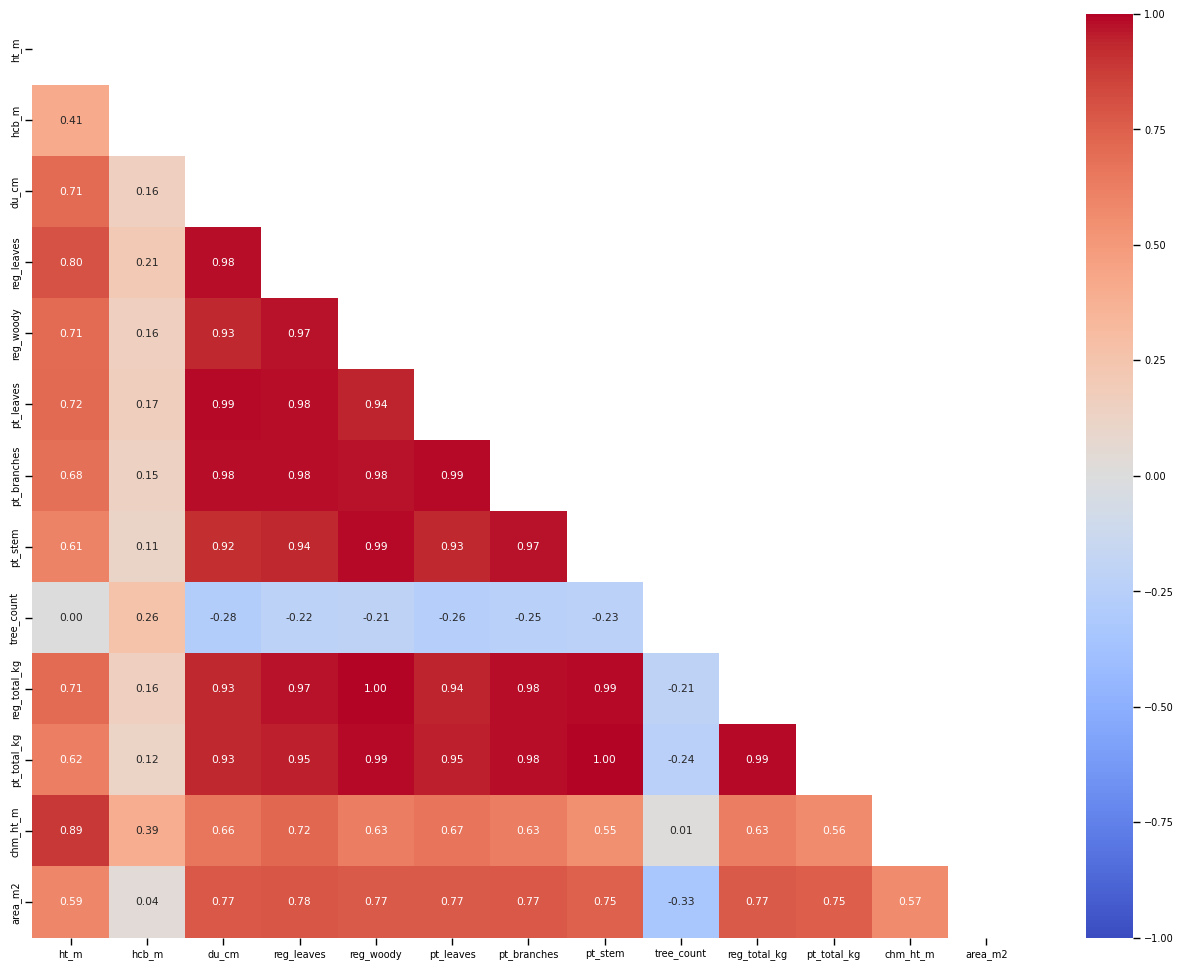

In [155]:
# make a heatmap of the correlation matrix for merged_data, exluding tree_id

corr_matrix = merged_data.drop(columns="tree_id").corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(16, 12))

# remove the correlation with self from the heatmap
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.show()

In [156]:
# remove reg_leaves, reg_woody, pt_leaves, pt_branches, pt_stem from field_variables
field_biomass_total = merged_data.drop(columns=['reg_leaves', 'reg_woody', 'pt_leaves', 'pt_branches', 'pt_stem'])
field_biomass_total.head()

,tree_id,ht_m,hcb_m,du_cm,tree_count,reg_total_kg,pt_total_kg,chm_ht_m,area_m2
0,p10t1,5.1,1.9,11.30,35,55.48,46.32,8.169987,3.797820
1,p10t2,10.4,2.5,42.30,35,1358.32,1323.96,10.110493,25.516840
2,p10t3,10.0,3.2,58.80,35,2589.87,2990.72,10.595913,23.658146
3,p10t4,5.4,1.8,9.80,35,43.69,36.20,5.052254,4.097521
4,p10t5,6.9,1.9,15.72,35,134.37,113.34,6.530582,7.422642


In [157]:
#  create counts for each variable in field_biomass_total, excluding tree_id
variable_counts = field_biomass_total.drop(columns='tree_id').count()
variable_counts

ht_m            266
hcb_m           266
du_cm           266
tree_count      266
reg_total_kg    266
pt_total_kg     266
chm_ht_m        266
area_m2         266
dtype: int64

In [158]:
# drop the rows with na's in any of the columns in field_biomass_total
field_biomass_total = field_biomass_total.dropna()

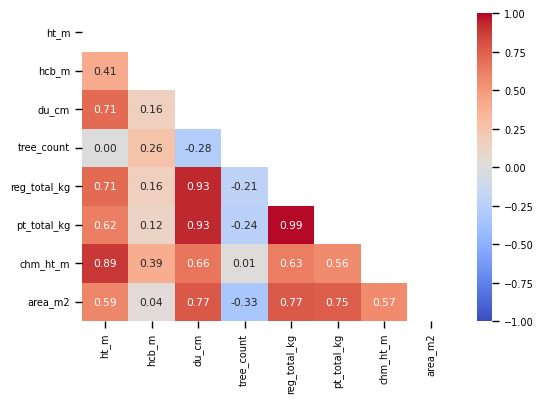

In [159]:
# run heatmap again for field_biomass_total
corr_matrix = field_biomass_total.drop(columns="tree_id").corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(6, 4))
# sns.heatmap(correlation_matrix, ax=ax, annot=True, fmt='.2f')
# ax.tick_params(axis='both', labelsize=6)

# remove the correlation with self from the heatmap
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.show()

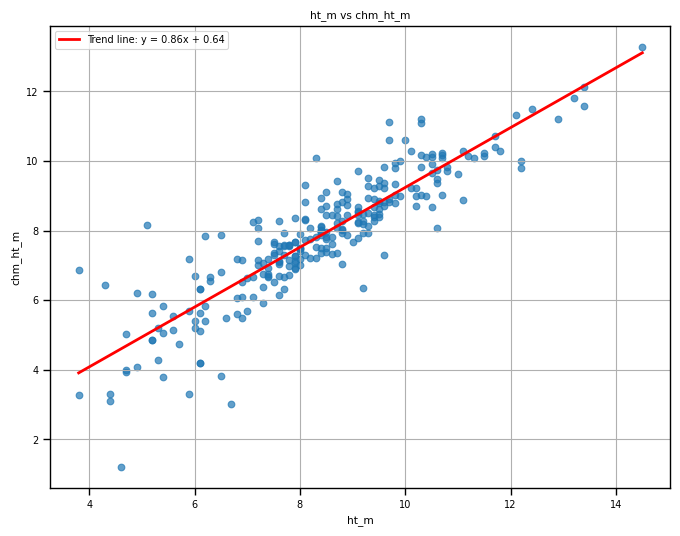

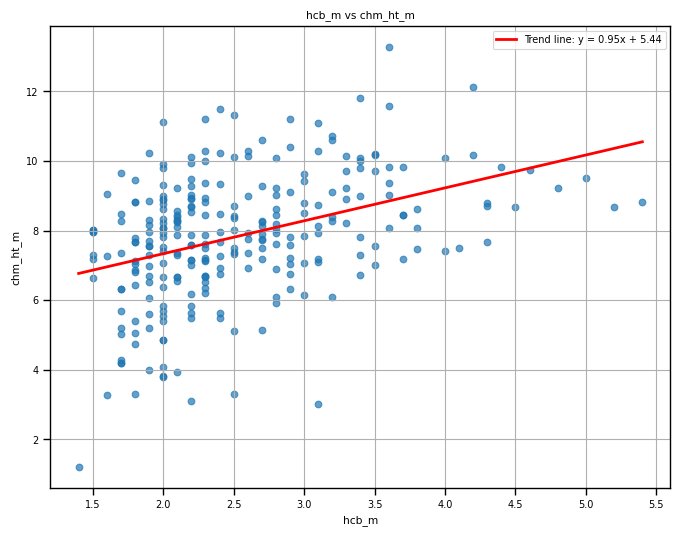

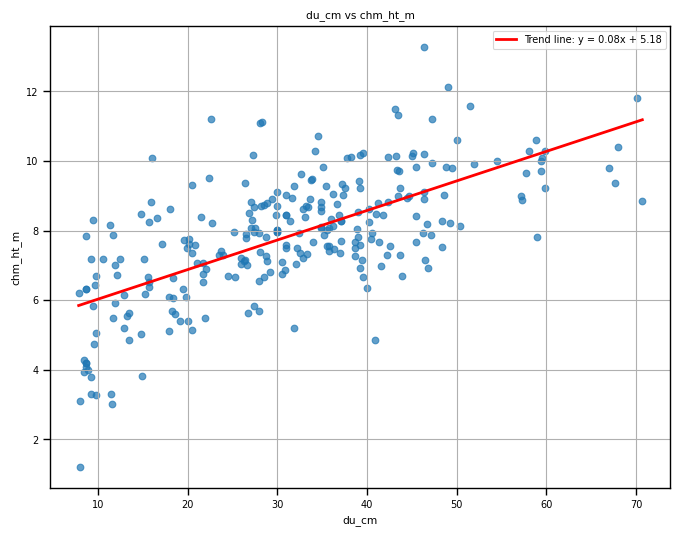

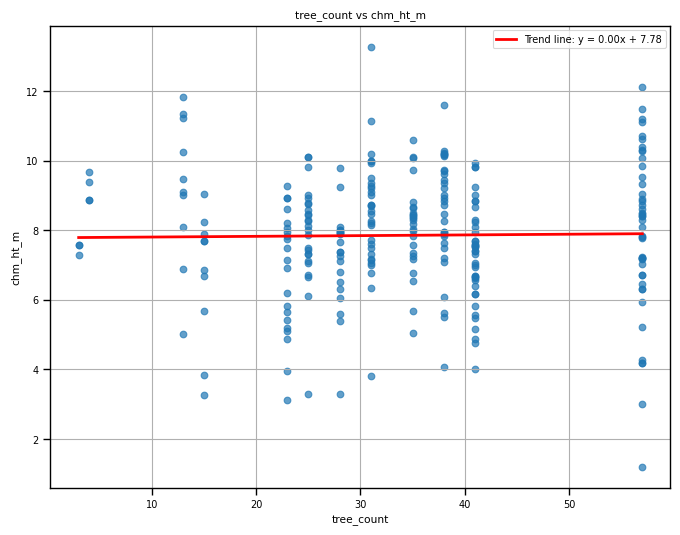

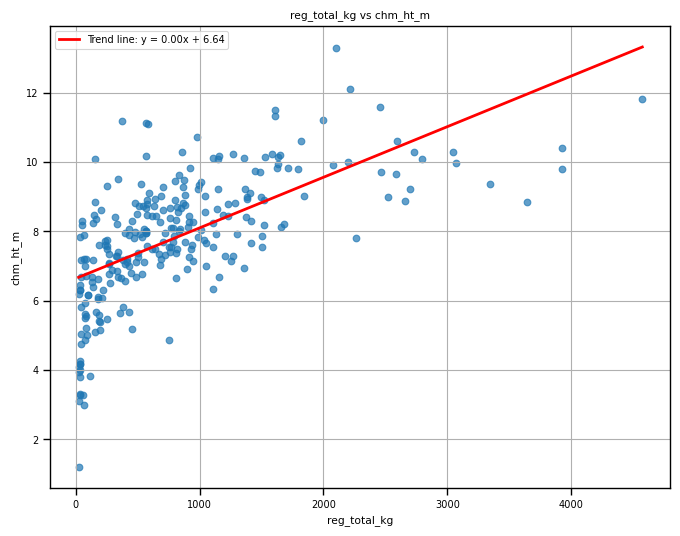

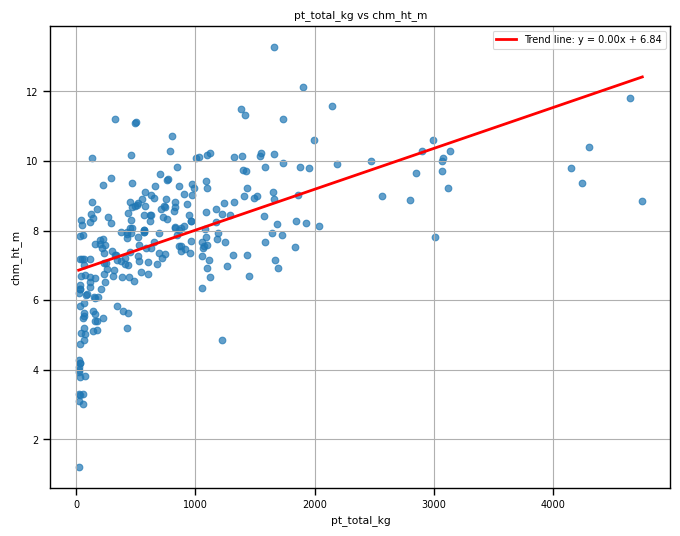

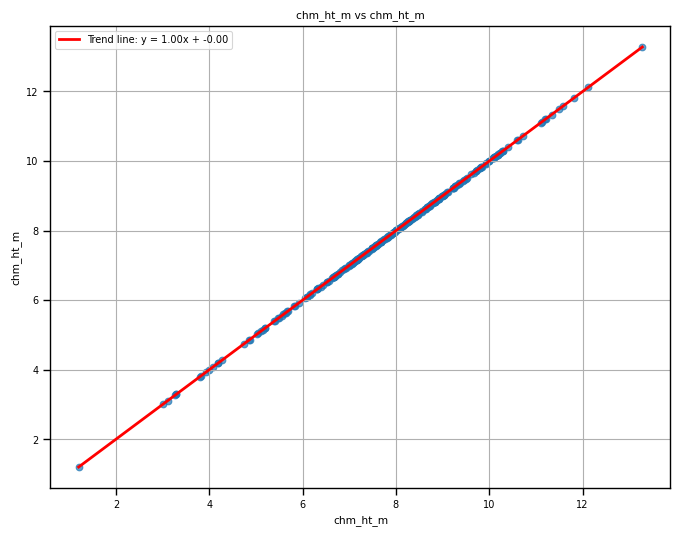

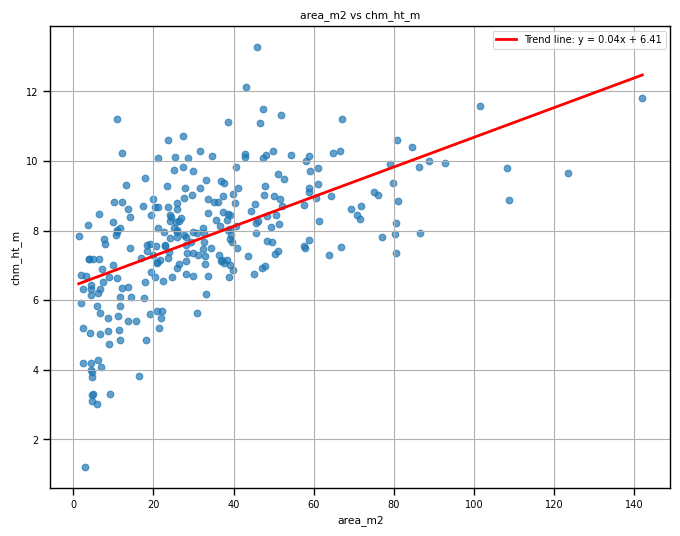

In [160]:
# create scatter plots for each variable in field_biomass_total against chm_heightsmax, with a trend line
for column in field_biomass_total.columns:
    if column != 'tree_id':
        plt.figure(figsize=(8, 6))
        plt.scatter(field_biomass_total[column], field_biomass_total['chm_ht_m'], alpha=0.7)
        plt.xlabel(column)
        plt.ylabel('chm_ht_m')
        plt.title(f'{column} vs chm_ht_m')
        
        # Fit a linear trend line
        coeffs = np.polyfit(field_biomass_total[column].dropna(), field_biomass_total['chm_ht_m'].dropna(), 1)
        trend_x = np.linspace(field_biomass_total[column].min(), field_biomass_total[column].max(), 100)
        trend_y = np.polyval(coeffs, trend_x)
        plt.plot(trend_x, trend_y, color='red', linewidth=2, label=f'Trend line: y = {coeffs[0]:.2f}x + {coeffs[1]:.2f}')
        
        plt.legend()
        plt.grid(True)
        plt.show()

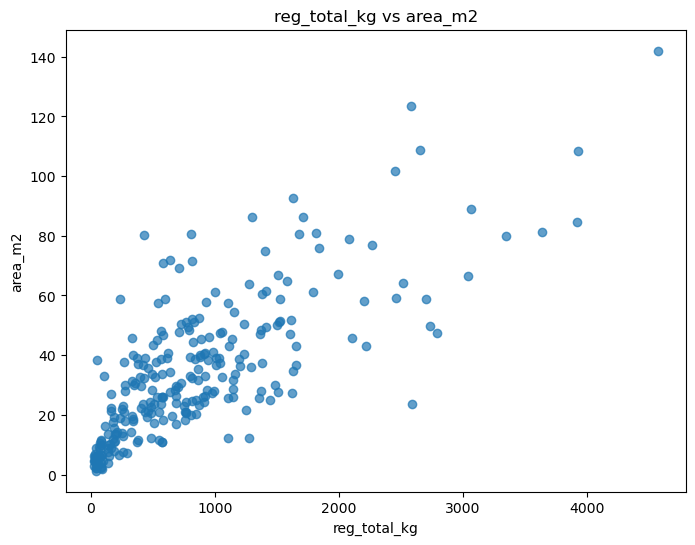

In [98]:
# plot a scatter plot of reg_total_kg against area_m2 and chm_heightsmax, with a trend line for each
plt.figure(figsize=(8, 6))
plt.scatter(field_biomass_total['reg_total_kg'], field_biomass_total['area_m2'], alpha=0.7)
plt.xlabel('reg_total_kg')
plt.ylabel('area_m2')
plt.title('reg_total_kg vs area_m2')
# Fit a linear trend line
coeffs = np.polyfit(field_biomass_total['reg_total_kg'].dropna(), field_biomass_total['area_m2'].dropna(), 1)
trend_x = np.linspace(field_biomass_total['reg_total_kg'].min(), field_biomass_total['reg_total_kg'].max(), 100)
trend_y = np.polyval(coeffs, trend_x)

In [161]:
# calculate the r-squared, mean error, rmse, and standard deviation of the correlation between ht_m and chm_ht_m
r_squared = field_biomass_total['ht_m'].corr(field_biomass_total['chm_ht_m']) ** 2
mean_error = (field_biomass_total['ht_m'] - field_biomass_total['chm_ht_m']).mean()
rmse = np.sqrt(((field_biomass_total['ht_m'] - field_biomass_total['chm_ht_m']) ** 2).mean())
std_dev = field_biomass_total['ht_m'].std()
print(f"R-squared: {r_squared:.4f}")
print(f"Mean Error: {mean_error:.4f}")
print(f"RMSE: {rmse:.4f}") 
print(f"Standard Deviation: {std_dev:.4f}")

R-squared: 0.7877
Mean Error: 0.5339
RMSE: 1.0203
Standard Deviation: 1.8616
